# The University of Azad Jammu and Kashmir
### Department of Software Engineering
**Digital Image Processing Lab** Lab Instructor: Engr. Fahad Nisar    
Semester: Fifth | Session: 2024-28 (SE)

**Name:** Jawahir Ali  |  **Roll No:** 2024-SE-34

---
## Lab Task # 04 – Geometric Transformations with Custom Inputs
Assigned: Nov 05, 2026 | Due: Nov 12, 2026, 11:59 PM

**Objective:** build one reusable `transform(image, operation, **params)` function that takes custom values, validates them, and performs scaling, cropping, flipping, translation and rotation.

**Contents:** 1 Load and validate the image · 2 The `transform` function · 3 Text input layer and interactive prompts · 4 Demonstration of every operation (saved to `outputs/`) · 5 Interpolation comparison · 6 Rejected inputs · 7 Identity checks · 8 Concepts · 9 Final check

## 1. Load the image and validate it
The file must exist, decode successfully and have non-zero dimensions. OpenCV decodes to **BGR**, so the image is converted to **RGB once, here**, and RGB is used everywhere after (display with Matplotlib, and converted back to BGR only when saving with `cv2.imwrite`). The original is made read-only so it cannot be altered by accident.

load_image_rgb('does_not_exist.png') -> FileNotFoundError: Image file not found: 'does_not_exist.png'
load_image_rgb('C:\\Users\\JAWAH_~1\\AppData\\Local\\Temp\\not_an_image.png') -> ValueError: File exists but could not be decoded as an image: 'C:\\Users\\JAWAH_~1\\AppData\\Local\\Temp\\not_an_image.png'

Loaded image.jpg:  width = 596,  height = 335,  array shape = (335, 596, 3) (rows, cols, channels),  dtype = uint8


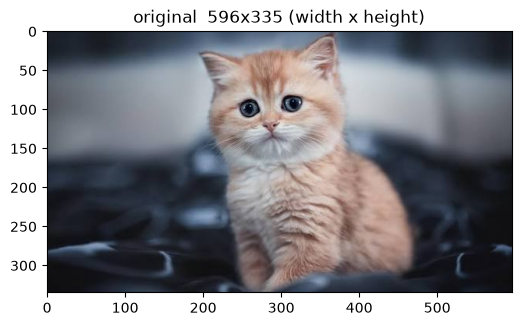

In [1]:
import os, math, numbers
import numpy as np
import cv2
import matplotlib.pyplot as plt

IMAGE_PATH = "image.jpg"

def load_image_rgb(path):
    if not isinstance(path, (str, os.PathLike)):
        raise ValueError("Image path must be a string.")
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Image file not found: {path!r}")
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)                 # always 3 channels, BGR order
    if bgr is None:
        raise ValueError(f"File exists but could not be decoded as an image: {path!r}")
    if bgr.ndim < 2 or bgr.shape[0] == 0 or bgr.shape[1] == 0:
        raise ValueError(f"Image has zero width or height: shape={bgr.shape}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)              # consistent colour handling: RGB from here on

# the loader's own error handling, shown on bad paths
import tempfile
fake = os.path.join(tempfile.gettempdir(), "not_an_image.png")        # exists, but is plain text, not a real PNG
open(fake, "w").write("this is not an image")
for bad in ["does_not_exist.png", fake]:
    try:
        load_image_rgb(bad)
    except Exception as e:
        print(f"load_image_rgb({bad!r}) -> {type(e).__name__}: {e}")

original = load_image_rgb(IMAGE_PATH)
original_backup = original.copy()                            # used at the end to prove it was never modified
original.flags.writeable = False

H, W = original.shape[:2]
print(f"\nLoaded {IMAGE_PATH}:  width = {W},  height = {H},  array shape = {original.shape} (rows, cols, channels),  dtype = {original.dtype}")
plt.figure(figsize=(6, 4)); plt.imshow(original); plt.title(f"original  {W}x{H} (width x height)"); plt.show()

## 2. The reusable `transform` function
One entry point: `transform(image, operation, **params)` returns the transformed image.

| operation | required parameters | rules |
|---|---|---|
| `"scale"` | `sx`, `sy`, `interpolation` | finite factors > 0; output size `round(W·sx) × round(H·sy)` must be ≥ 1 px and within the maximum; interpolation ∈ nearest / bilinear / bicubic / lanczos |
| `"crop"` | `left`, `top`, `right`, `bottom` | integers, `0 ≤ left < right ≤ W`, `0 ≤ top < bottom ≤ H` (right and bottom exclusive) |
| `"flip"` | `direction` | `"horizontal"`, `"vertical"` or `"both"` |
| `"translate"` | `tx`, `ty` | any finite number (negative and zero are valid); canvas size unchanged; image must stay at least partly on the canvas |
| `"rotate"` | `angle`, `expand` | any finite angle in degrees (negative and zero valid); `expand` must be a bool; centre rotation; **positive = counter-clockwise** |

**Validation policy:** unknown operations, missing parameters and *unexpected* parameters are all rejected; there are **no silent defaults**. **Maximum output size:** `MAX_SIDE = 4096` px per side and `MAX_PIXELS = 16 000 000`. Every error is raised as `TransformError` with a clear message.

Translation and rotation are built as 2×3 **affine matrices** and applied with `cv2.warpAffine` (bilinear sampling, uncovered areas filled with black). Rotation is about the image centre `((W−1)/2, (H−1)/2)`.

In [2]:
MAX_SIDE   = 4096
MAX_PIXELS = 16_000_000
INTERPOLATIONS = {"nearest": cv2.INTER_NEAREST, "bilinear": cv2.INTER_LINEAR,
                  "bicubic": cv2.INTER_CUBIC,  "lanczos": cv2.INTER_LANCZOS4}
DIRECTIONS = {"horizontal": 1, "vertical": 0, "both": -1}          # cv2.flip codes

class TransformError(ValueError):
    """Raised for any invalid image, operation or parameter."""

# ---------- per-parameter validators (shared by the text layer AND by transform) ----------
def _is_number(v):
    return isinstance(v, numbers.Real) and not isinstance(v, (bool, np.bool_))

def v_number(name, v):
    if not _is_number(v):
        raise TransformError(f"'{name}' must be a number, got {v!r} ({type(v).__name__})")
    f = float(v)
    if not math.isfinite(f):
        raise TransformError(f"'{name}' must be finite (NaN and infinity are not allowed), got {v!r}")
    return f

def v_positive(name, v):
    f = v_number(name, v)
    if f <= 0:
        raise TransformError(f"'{name}' must be greater than 0, got {v!r}")
    return f

def v_int(name, v):
    if isinstance(v, (bool, np.bool_)) or not isinstance(v, numbers.Integral):
        raise TransformError(f"'{name}' must be a whole number (integer), got {v!r}")
    return int(v)

def v_choice(name, v, choices):
    if not isinstance(v, str):
        raise TransformError(f"'{name}' must be text, one of {sorted(choices)}; got {v!r}")
    key = v.strip().lower()
    if key not in choices:
        raise TransformError(f"unsupported {name} {v!r}; choose one of {sorted(choices)}")
    return key

def v_interp(name, v):    return v_choice(name, v, INTERPOLATIONS)
def v_direction(name, v): return v_choice(name, v, DIRECTIONS)
def v_bool(name, v):
    if not isinstance(v, (bool, np.bool_)):
        raise TransformError(f"'{name}' must be True or False, got {v!r}")
    return bool(v)

# operation -> ordered {parameter: validator}
OPERATIONS = {
    "scale":     {"sx": v_positive, "sy": v_positive, "interpolation": v_interp},
    "crop":      {"left": v_int, "top": v_int, "right": v_int, "bottom": v_int},
    "flip":      {"direction": v_direction},
    "translate": {"tx": v_number, "ty": v_number},
    "rotate":    {"angle": v_number, "expand": v_bool},
}

def _check_image(img):
    if not isinstance(img, np.ndarray):
        raise TransformError("image must be a NumPy array")
    if img.dtype != np.uint8:
        raise TransformError(f"image must be uint8, got {img.dtype}")
    if img.ndim not in (2, 3) or (img.ndim == 3 and img.shape[2] not in (1, 3, 4)):
        raise TransformError(f"unsupported image shape {img.shape}")
    if img.shape[0] == 0 or img.shape[1] == 0:
        raise TransformError(f"image has zero width or height: shape {img.shape}")

def _check_output_size(w, h, what="output"):
    if w < 1 or h < 1:
        raise TransformError(f"{what} would be empty: {w}x{h} px (both sides must be at least 1)")
    if w > MAX_SIDE or h > MAX_SIDE or w * h > MAX_PIXELS:
        raise TransformError(f"{what} {w}x{h} px exceeds the maximum allowed "
                             f"({MAX_SIDE} px per side, {MAX_PIXELS:,} px total)")

def transform(image, operation, **params):
    """Apply one geometric operation. Returns the new image; the input is never modified."""
    _check_image(image)
    if not isinstance(operation, str) or operation.strip().lower() not in OPERATIONS:
        raise TransformError(f"unknown operation {operation!r}; supported: {sorted(OPERATIONS)}")
    op = operation.strip().lower()
    spec = OPERATIONS[op]
    missing = [p for p in spec if p not in params]
    extra   = [p for p in params if p not in spec]
    if missing: raise TransformError(f"'{op}' is missing required parameter(s): {missing}")
    if extra:   raise TransformError(f"'{op}' got unexpected parameter(s): {extra}; expected {list(spec)}")
    p = {name: check(name, params[name]) for name, check in spec.items()}      # validate every value
    h, w = image.shape[:2]

    if op == "scale":
        ow_f, oh_f = w * p["sx"], h * p["sy"]
        if ow_f > MAX_SIDE * 2 or oh_f > MAX_SIDE * 2:                          # avoid absurd/overflowing numbers
            raise TransformError(f"scaled size {ow_f:.4g}x{oh_f:.4g} px exceeds the maximum ({MAX_SIDE} px per side)")
        ow, oh = int(round(ow_f)), int(round(oh_f))
        _check_output_size(ow, oh, f"scaled image ({w}x{h} x {p['sx']:g}, {p['sy']:g})")
        return cv2.resize(image, (ow, oh), interpolation=INTERPOLATIONS[p["interpolation"]])   # dsize is (width, height)!

    if op == "crop":
        l, t, r, b = p["left"], p["top"], p["right"], p["bottom"]
        if not (0 <= l < r <= w):
            raise TransformError(f"invalid horizontal crop: need 0 <= left < right <= width({w}), got left={l}, right={r}")
        if not (0 <= t < b <= h):
            raise TransformError(f"invalid vertical crop: need 0 <= top < bottom <= height({h}), got top={t}, bottom={b}")
        return image[t:b, l:r].copy()                                           # rows = y, columns = x; right/bottom exclusive

    if op == "flip":
        return cv2.flip(image, DIRECTIONS[p["direction"]])

    if op == "translate":
        tx, ty = p["tx"], p["ty"]
        if abs(tx) >= w or abs(ty) >= h:
            raise TransformError(f"translation ({tx:g}, {ty:g}) moves the whole image off the {w}x{h} canvas "
                                 f"(need |tx| < {w} and |ty| < {h})")
        M = np.float64([[1, 0, tx], [0, 1, ty]])
        return cv2.warpAffine(image, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

    if op == "rotate":
        angle = math.fmod(p["angle"], 360.0)                                    # same rotation, avoids huge-angle noise
        centre = ((w - 1) / 2.0, (h - 1) / 2.0)
        M = cv2.getRotationMatrix2D(centre, angle, 1.0)                         # positive angle = counter-clockwise
        ow, oh = w, h
        if p["expand"]:
            c, s = abs(M[0, 0]), abs(M[0, 1])
            ow = int(math.ceil(round(h * s + w * c, 6)))
            oh = int(math.ceil(round(h * c + w * s, 6)))
            _check_output_size(ow, oh, "expanded rotated canvas")
            M[0, 2] += (ow - w) / 2.0                                           # re-centre the rotated image on the bigger canvas
            M[1, 2] += (oh - h) / 2.0
        return cv2.warpAffine(image, M, (ow, oh), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

# smoke test
out = transform(original, "flip", direction="horizontal")
print("transform(...) works:", out.shape, out.dtype, "| input still unchanged:", np.array_equal(original, original_backup))

transform(...) works: (335, 596, 3) uint8 | input still unchanged: True


## 3. Custom input: text parsing and interactive prompts
Values typed by the user are text, so a **text layer** first converts them (`"abc"`, `"nan"`, `"inf"` and empty strings are rejected there with a clear message) and then runs the same per-parameter validators used inside `transform`. Cross-checks that need the image (crop bounds, output size) happen inside `transform`. A bad entry never crashes the session: the message is shown and the user is asked again.

`interactive_session()` uses Python's `input()`. So that this notebook runs unattended and is reproducible, the demo below feeds it a **scripted list of typed answers** (`SCRIPTED_ANSWERS`), including wrong ones, which are echoed after each prompt exactly as if typed. **To type your own values, set `SCRIPTED_ANSWERS = None` and re-run that cell.**

In [3]:
def parse_text(name, text, validator):
    """Convert user-typed text into a Python value for the given validator, or raise TransformError."""
    if text is None or not str(text).strip():
        raise TransformError(f"'{name}' is required; nothing was entered")
    text = str(text).strip()
    if validator is v_int:
        try:    value = int(text)
        except ValueError: raise TransformError(f"'{name}' must be a whole number, got {text!r}") from None
    elif validator in (v_number, v_positive):
        try:    value = float(text)
        except ValueError: raise TransformError(f"'{name}' must be a number, got {text!r} (not numeric)") from None
    elif validator is v_bool:
        low = text.lower()
        if low in ("true", "yes", "y", "1"):    value = True
        elif low in ("false", "no", "n", "0"):  value = False
        else: raise TransformError(f"'{name}' must be yes/no (or true/false), got {text!r}")
    else:
        value = text                                                  # choices are validated as text
    return validator(name, value)                                    # finite / positive / allowed-choice checks

def run_from_text(operation, raw):
    """raw: dict of parameter -> typed text. Parse, validate, then call transform."""
    if operation not in OPERATIONS:
        raise TransformError(f"unknown operation {operation!r}; supported: {sorted(OPERATIONS)}")
    params = {n: parse_text(n, raw.get(n), v) for n, v in OPERATIONS[operation].items()}
    return transform(original, operation, **params), params

HINTS = {"sx": "horizontal scale factor (>0)", "sy": "vertical scale factor (>0)", "interpolation": "nearest/bilinear/bicubic/lanczos",
         "left": "left x (integer)", "top": "top y (integer)", "right": "right x, exclusive (integer)", "bottom": "bottom y, exclusive (integer)",
         "direction": "horizontal/vertical/both", "tx": "horizontal shift px (+ right, - left)", "ty": "vertical shift px (+ down, - up)",
         "angle": "degrees (+ counter-clockwise)", "expand": "expand canvas? yes/no"}

def interactive_session(scripted=None, results=None):
    answers = iter(scripted) if scripted is not None else None
    def ask(prompt):
        if answers is None:
            return input(prompt)
        try: a = next(answers)
        except StopIteration: raise EOFError("scripted answers exhausted")
        print(f"{prompt}{a}"); return a
    print(f"Image is {W}x{H}.  Operations: {sorted(OPERATIONS)}")
    while True:                                                       # 1) choose an operation
        op = ask("Operation: ").strip().lower()
        if op in OPERATIONS: break
        print(f"   ERROR: unknown operation {op!r}. Please choose one of {sorted(OPERATIONS)}")
    while True:                                                       # 2) enter parameters; a failed transform re-asks everything
        params = {}
        for name, validator in OPERATIONS[op].items():
            while True:
                text = ask(f"  {name} [{HINTS[name]}]: ")
                try:
                    params[name] = parse_text(name, text, validator); break
                except TransformError as e:
                    print(f"   ERROR: {e}  -> please re-enter")
        try:
            result = transform(original, op, **params)
            break
        except TransformError as e:
            print(f"   ERROR: {e}\n   -> please re-enter all {op} values")
    print(f"   OK: {op} {params} -> output {result.shape[1]}x{result.shape[0]}")
    if results is not None: results.append((op, params, result))
    return op, params, result

In [4]:
# ---- scripted "typed" answers (set SCRIPTED_ANSWERS = None to be prompted by input() instead) ----
SCRIPTED_ANSWERS = [
    # session 1: scale  (unknown operation, non-numeric, negative, NaN, bad interpolation, then valid)
    "zoom", "scale", "abc", "-2", "1.5", "nan", "1.5", "cubic?", "lanczos",
    # session 2: crop   (right <= left is caught by transform -> everything re-entered)
    "crop", "10", "20", "5", "150", "10", "20", "260", "170",
    # session 3: flip   (unsupported direction, then valid)
    "flip", "diagonal", "both",
    # session 4: translate (negative and zero offsets are valid; text "ten" is not)
    "translate", "-40", "ten", "0",
    # session 5: rotate (non-numeric angle, then a negative angle; bad yes/no, then yes)
    "rotate", "ninety", "-30", "maybe", "yes",
]
session_results = []
if SCRIPTED_ANSWERS is not None:
    feed = iter(SCRIPTED_ANSWERS)                  # ONE shared iterator: each session takes only the answers it needs
    for k in range(5):
        print(f"\n===== interactive session {k+1} =====")
        interactive_session(scripted=feed, results=session_results)
else:
    interactive_session(results=session_results)


===== interactive session 1 =====
Image is 596x335.  Operations: ['crop', 'flip', 'rotate', 'scale', 'translate']
Operation: zoom
   ERROR: unknown operation 'zoom'. Please choose one of ['crop', 'flip', 'rotate', 'scale', 'translate']
Operation: scale
  sx [horizontal scale factor (>0)]: abc
   ERROR: 'sx' must be a number, got 'abc' (not numeric)  -> please re-enter
  sx [horizontal scale factor (>0)]: -2
   ERROR: 'sx' must be greater than 0, got -2.0  -> please re-enter
  sx [horizontal scale factor (>0)]: 1.5
  sy [vertical scale factor (>0)]: nan
   ERROR: 'sy' must be finite (NaN and infinity are not allowed), got nan  -> please re-enter
  sy [vertical scale factor (>0)]: 1.5
  interpolation [nearest/bilinear/bicubic/lanczos]: cubic?
   ERROR: unsupported interpolation 'cubic?'; choose one of ['bicubic', 'bilinear', 'lanczos', 'nearest']  -> please re-enter
  interpolation [nearest/bilinear/bicubic/lanczos]: lanczos
   OK: scale {'sx': 1.5, 'sy': 1.5, 'interpolation': 'lanczos'

saved 5 interactive results to outputs/


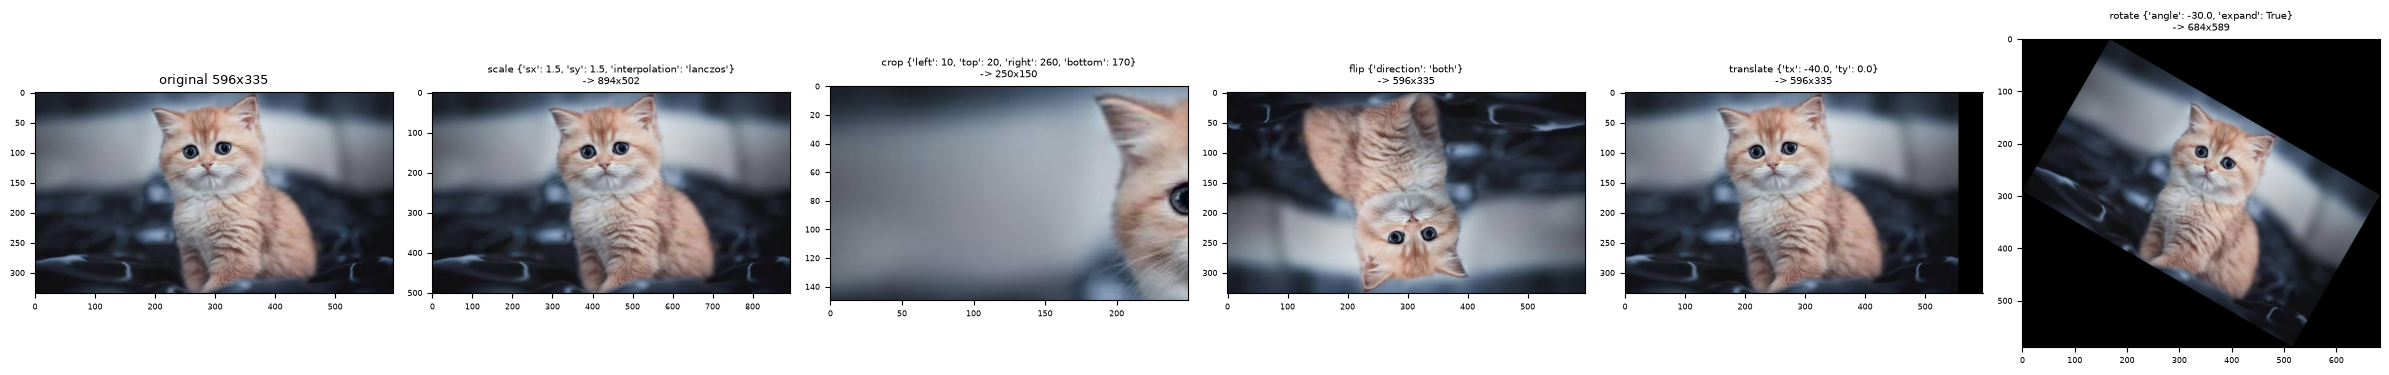

In [5]:
# show what the five interactive sessions produced
os.makedirs("outputs", exist_ok=True)
for i, (op, params, img) in enumerate(session_results, 1):                # save the interactive results as well
    cv2.imwrite(os.path.join("outputs", f"interactive{i}_{op}.png"), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
print("saved", len(session_results), "interactive results to outputs/")
fig, ax = plt.subplots(1, len(session_results) + 1, figsize=(4 * (len(session_results) + 1), 3.6))
ax[0].imshow(original); ax[0].set_title(f"original {W}x{H}", fontsize=9)
for a, (op, params, img) in zip(ax[1:], session_results):
    a.imshow(img); a.set_title(f"{op} {params}\n-> {img.shape[1]}x{img.shape[0]}", fontsize=7)
for a in ax: a.tick_params(labelsize=6)
plt.tight_layout(); plt.show()

## 4. Demonstration of every operation with custom values
Each result is shown next to the original with a label giving the operation, parameters and output dimensions (width × height), and saved to `outputs/` as PNG. The cases include enlargement and reduction (proportional and non-proportional scaling), shifts in opposite directions, and positive and negative rotations.

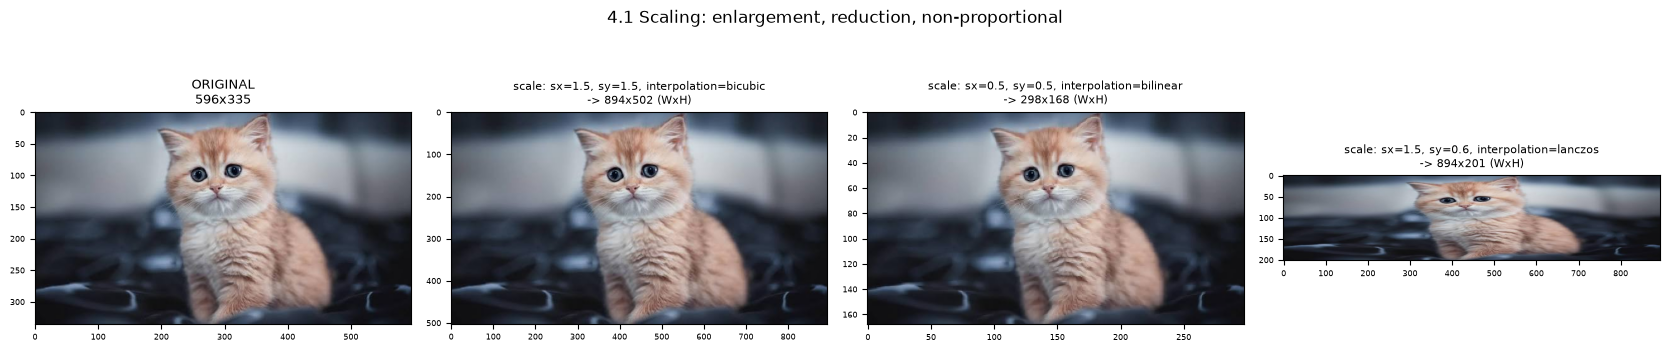

In [6]:
os.makedirs("outputs", exist_ok=True)
saved = []

def save_result(name, img):
    path = os.path.join("outputs", name + ".png")
    if not cv2.imwrite(path, cv2.cvtColor(img, cv2.COLOR_RGB2BGR)):            # back to BGR only for writing
        raise IOError(f"could not write {path}")
    saved.append((path, img.shape[1], img.shape[0])); return path

def fmt(v): return f"{v:g}" if isinstance(v, float) else str(v)

def demo(title, cases, ncols=None):
    """cases: list of (operation, params). Shows original + each result, labelled; saves each result."""
    n = len(cases) + 1
    fig, ax = plt.subplots(1, n, figsize=(4.2 * n, 4))
    ax[0].imshow(original); ax[0].set_title(f"ORIGINAL\n{W}x{H}", fontsize=9)
    for a, (op, params) in zip(ax[1:], cases):
        out = transform(original, op, **params)
        plabel = ", ".join(f"{k}={fmt(v)}" for k, v in params.items())
        a.imshow(out); a.set_title(f"{op}: {plabel}\n-> {out.shape[1]}x{out.shape[0]} (WxH)", fontsize=8)
        save_result(op + "_" + "_".join(f"{k}{fmt(v)}" for k, v in params.items()), out)
    for a in ax: a.tick_params(labelsize=6)
    fig.suptitle(title); plt.tight_layout(); plt.show()
    return

demo("4.1 Scaling: enlargement, reduction, non-proportional", [
    ("scale", dict(sx=1.5, sy=1.5, interpolation="bicubic")),       # proportional enlargement
    ("scale", dict(sx=0.5, sy=0.5, interpolation="bilinear")),      # proportional reduction
    ("scale", dict(sx=1.5, sy=0.6, interpolation="lanczos")),       # non-proportional: stretched wide, squashed short
])

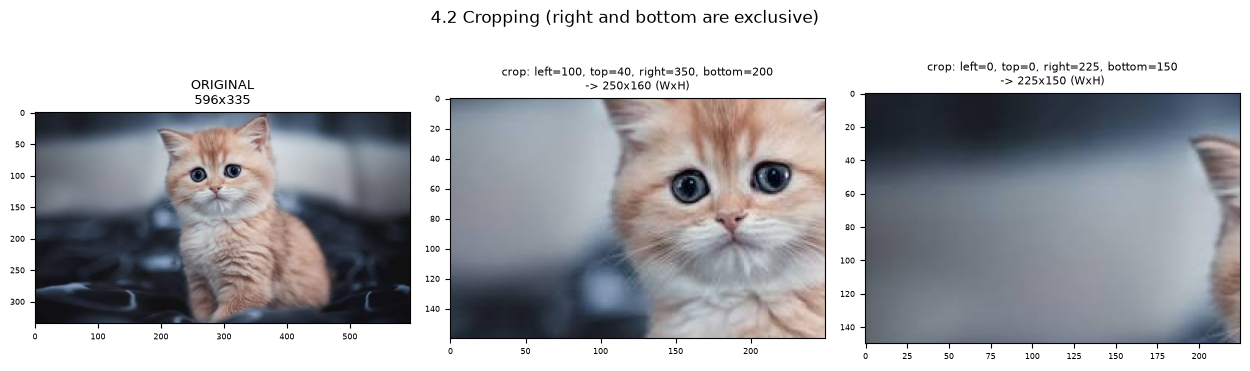

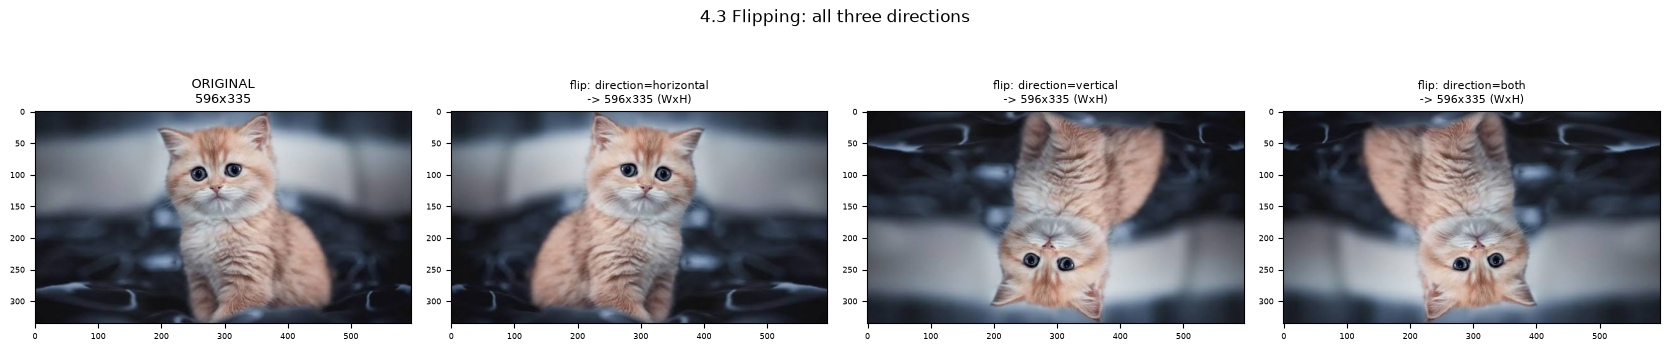

In [7]:
demo("4.2 Cropping (right and bottom are exclusive)", [
    ("crop", dict(left=100, top=40, right=350, bottom=200)),
    ("crop", dict(left=0, top=0, right=225, bottom=150)),
])
demo("4.3 Flipping: all three directions", [
    ("flip", dict(direction="horizontal")),
    ("flip", dict(direction="vertical")),
    ("flip", dict(direction="both")),
])

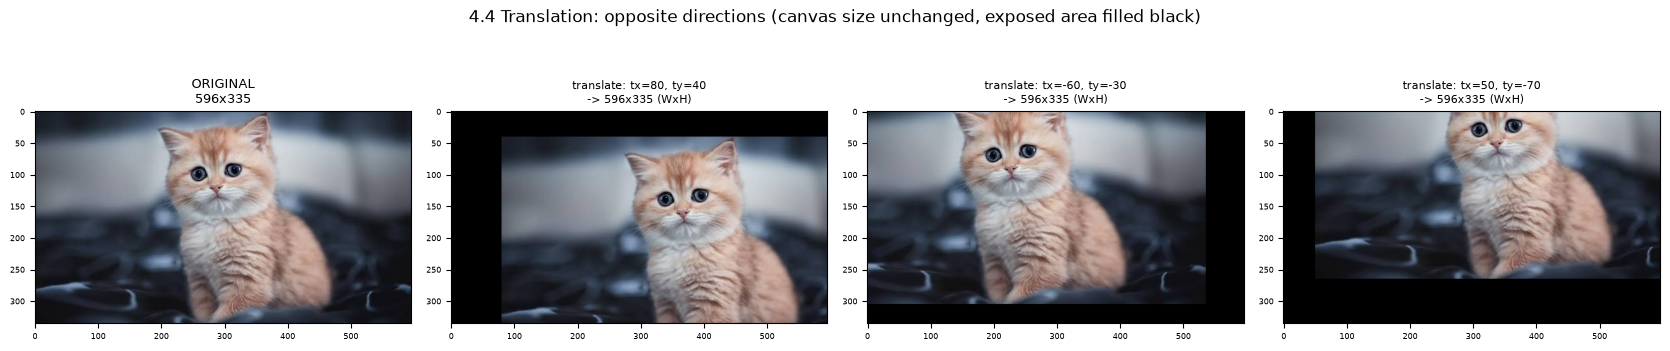

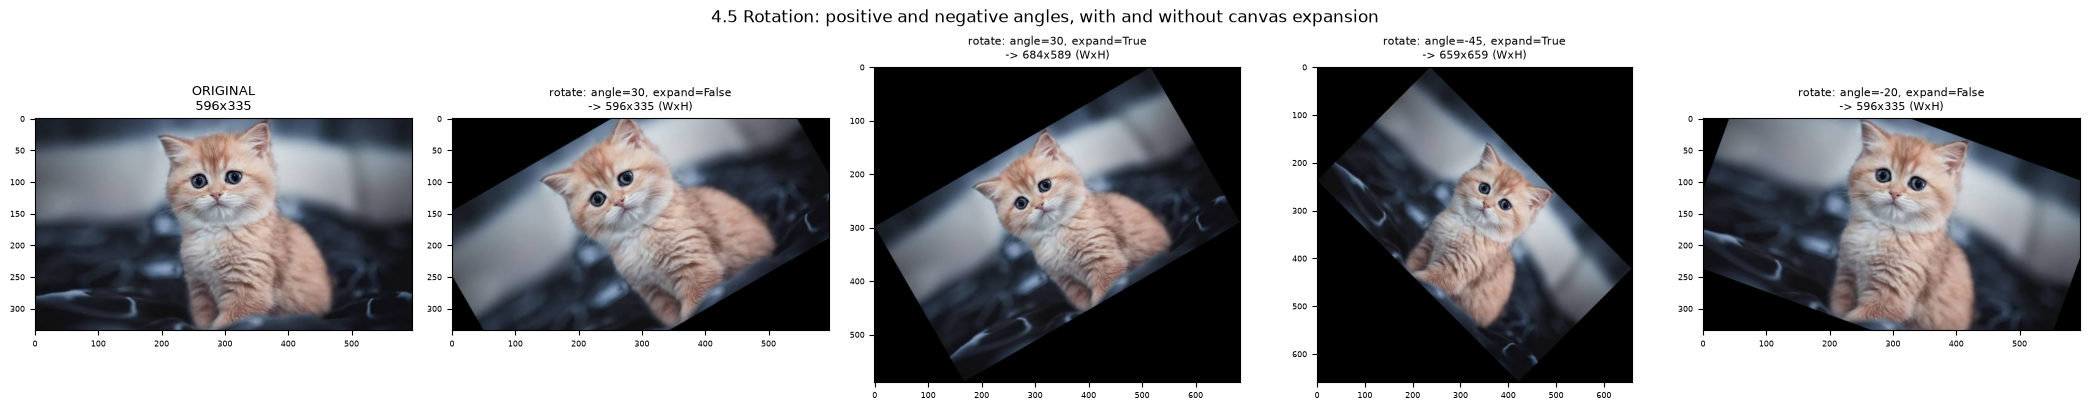

15 transformed images saved to outputs/:
  outputs\scale_sx1.5_sy1.5_interpolationbicubic.png      894x502
  outputs\scale_sx0.5_sy0.5_interpolationbilinear.png     298x168
  outputs\scale_sx1.5_sy0.6_interpolationlanczos.png      894x201
  outputs\crop_left100_top40_right350_bottom200.png       250x160
  outputs\crop_left0_top0_right225_bottom150.png          225x150
  outputs\flip_directionhorizontal.png                    596x335
  outputs\flip_directionvertical.png                      596x335
  outputs\flip_directionboth.png                          596x335
  outputs\translate_tx80_ty40.png                         596x335
  outputs\translate_tx-60_ty-30.png                       596x335
  outputs\translate_tx50_ty-70.png                        596x335
  outputs\rotate_angle30_expandFalse.png                  596x335
  outputs\rotate_angle30_expandTrue.png                   684x589
  outputs\rotate_angle-45_expandTrue.png                  659x659
  outputs\rotate_angle-20_expandFal

In [8]:
demo("4.4 Translation: opposite directions (canvas size unchanged, exposed area filled black)", [
    ("translate", dict(tx=80, ty=40)),          # right and down
    ("translate", dict(tx=-60, ty=-30)),        # left and up
    ("translate", dict(tx=50, ty=-70)),         # right and up
])
demo("4.5 Rotation: positive and negative angles, with and without canvas expansion", [
    ("rotate", dict(angle=30, expand=False)),   # counter-clockwise, corners clipped
    ("rotate", dict(angle=30, expand=True)),    # counter-clockwise, canvas grows
    ("rotate", dict(angle=-45, expand=True)),   # clockwise
    ("rotate", dict(angle=-20, expand=False)),
])
print(f"{len(saved)} transformed images saved to outputs/:")
for path, w, h in saved: print(f"  {path:55s} {w}x{h}")

## 5. Interpolation comparison on the same enlarged patch
A 40×40 patch around the cat's eye (columns 240–280, rows 79–119, which includes the sharp dark rim and pupil of the left eye) is enlarged **8×** with each interpolation method through the same `transform` function.

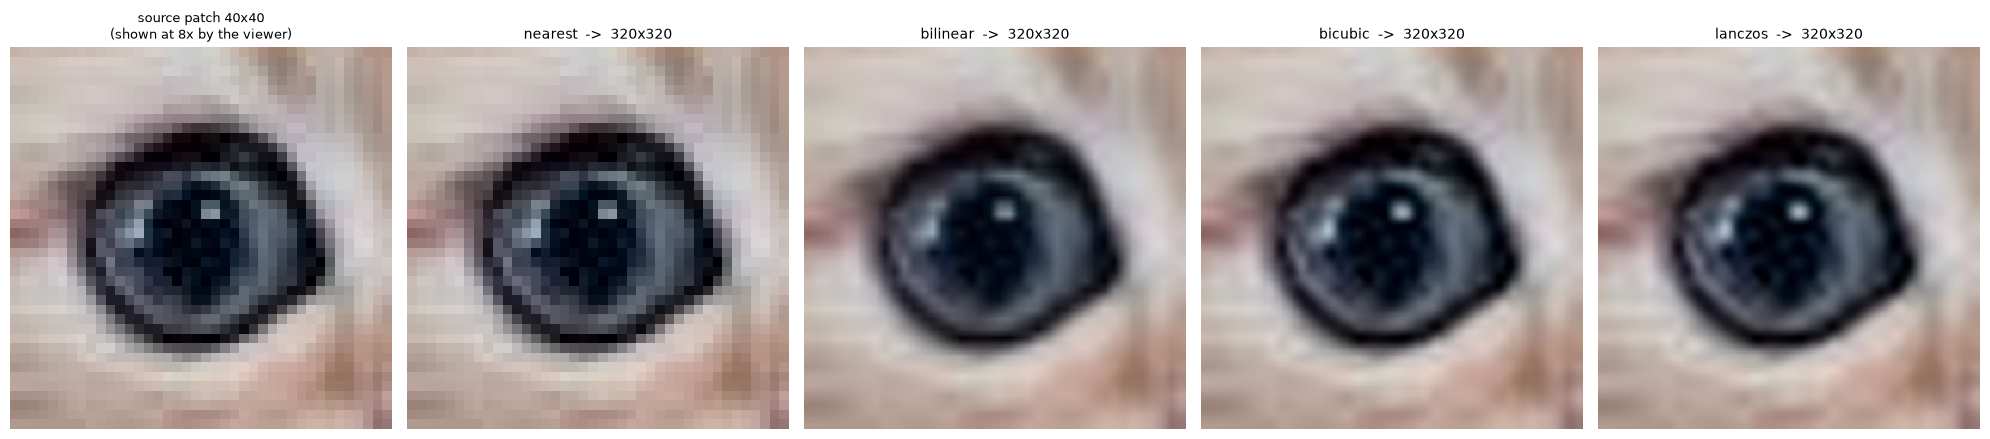

nearest   distinct colours =  1426   share of identical neighbours = 0.88
bilinear  distinct colours = 34257   share of identical neighbours = 0.19
bicubic   distinct colours = 36611   share of identical neighbours = 0.17
lanczos   distinct colours = 36951   share of identical neighbours = 0.17


In [9]:
patch = transform(original, "crop", left=240, top=79, right=280, bottom=119)
fig, ax = plt.subplots(1, 5, figsize=(20, 4.4))
ax[0].imshow(patch); ax[0].set_title(f"source patch {patch.shape[1]}x{patch.shape[0]}\n(shown at 8x by the viewer)", fontsize=9)
enlarged = {}
for a, name in zip(ax[1:], INTERPOLATIONS):
    big = transform(patch, "scale", sx=8, sy=8, interpolation=name)
    enlarged[name] = big
    a.imshow(big, interpolation="nearest"); a.set_title(f"{name}  ->  {big.shape[1]}x{big.shape[0]}", fontsize=10)
    save_result(f"interp_{name}_8x", big)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# a number to back up what the eye sees: how many distinct colours does each enlargement contain, and how blocky is it?
for name, big in enlarged.items():
    distinct = len(np.unique(big.reshape(-1, 3), axis=0))
    step = np.abs(np.diff(big.astype(int), axis=1)).sum(-1)               # horizontal pixel-to-pixel change
    print(f"{name:9s} distinct colours = {distinct:5d}   share of identical neighbours = {(step == 0).mean():.2f}")

**Visible differences (eye patch, 8× enlargement).**
* **Nearest-neighbour** copies the closest source pixel, so the result is made of clear square blocks; the dark rim of the eye and the small white highlights are staircase-shaped. It adds no new colours (only 1426 distinct colours, and 88 % of horizontally neighbouring pixels are identical).
* **Bilinear** averages the 4 nearest pixels, so it is smooth with no blocks, but it is the softest/blurriest of the four: the dark rim and the highlights look blurred.
* **Bicubic** uses 16 neighbours; it is smooth like bilinear but the dark rim and the fur strands at the bottom-left are visibly crisper.
* **Lanczos** (8×8 neighbours) is the sharpest of the smooth methods, with the most edge contrast at the dark rim and highlights; this extra sharpening can create faint halos (ringing) next to very bright spots.

Ranking for smoothness: nearest (blocky) < bicubic ≈ Lanczos (sharp) < bilinear (soft); the smooth methods have 34 000+ distinct colours because they invent in-between values.

## 6. Rejected inputs: at least one for every operation
Each case calls `transform` directly (or the text layer for typed input) with an invalid value. Every one must raise a clear `TransformError`; none may crash or be silently replaced with a default.

In [10]:
def expect_reject(label, fn):
    try:
        fn()
        print(f"[NOT REJECTED - BUG] {label}")
        return False
    except TransformError as e:
        print(f"[rejected] {label}\n           -> {e}")
        return True

cases = [
  # --- generic ---
  ("unknown operation 'shear'",                    lambda: transform(original, "shear", angle=10)),
  ("missing parameter (scale without sy)",         lambda: transform(original, "scale", sx=2, interpolation="bilinear")),
  ("unexpected parameter (flip with angle)",       lambda: transform(original, "flip", direction="both", angle=5)),
  ("image is None / not an array",                 lambda: transform(None, "flip", direction="both")),
  ("image with zero size",                         lambda: transform(np.zeros((0, 5, 3), np.uint8), "flip", direction="both")),
  # --- scale ---
  ("scale: factor 0",                              lambda: transform(original, "scale", sx=0, sy=1, interpolation="bilinear")),
  ("scale: negative factor",                       lambda: transform(original, "scale", sx=-1.5, sy=1, interpolation="bilinear")),
  ("scale: NaN factor",                            lambda: transform(original, "scale", sx=float("nan"), sy=1, interpolation="bilinear")),
  ("scale: infinite factor",                       lambda: transform(original, "scale", sx=1, sy=float("inf"), interpolation="bilinear")),
  ("scale: non-numeric factor ('big')",            lambda: transform(original, "scale", sx="big", sy=1, interpolation="bilinear")),
  ("scale: factor so small the image is empty",    lambda: transform(original, "scale", sx=0.001, sy=0.001, interpolation="bilinear")),
  ("scale: output larger than the maximum size",   lambda: transform(original, "scale", sx=20, sy=20, interpolation="bilinear")),
  ("scale: unsupported interpolation 'cubic'",     lambda: transform(original, "scale", sx=2, sy=2, interpolation="cubic")),
  # --- crop ---
  ("crop: right <= left",                          lambda: transform(original, "crop", left=200, top=0, right=100, bottom=100)),
  ("crop: right beyond width",                     lambda: transform(original, "crop", left=0, top=0, right=W + 1, bottom=100)),
  ("crop: negative left",                          lambda: transform(original, "crop", left=-5, top=0, right=100, bottom=100)),
  ("crop: bottom == top (empty)",                  lambda: transform(original, "crop", left=0, top=50, right=100, bottom=50)),
  ("crop: non-integer coordinate 10.5",            lambda: transform(original, "crop", left=10.5, top=0, right=100, bottom=100)),
  # --- flip ---
  ("flip: unsupported direction 'diagonal'",       lambda: transform(original, "flip", direction="diagonal")),
  ("flip: direction is a number",                  lambda: transform(original, "flip", direction=1)),
  # --- translate ---
  ("translate: non-numeric tx ('left')",           lambda: transform(original, "translate", tx="left", ty=0)),
  ("translate: NaN ty",                            lambda: transform(original, "translate", tx=0, ty=float("nan"))),
  ("translate: infinite tx",                       lambda: transform(original, "translate", tx=float("-inf"), ty=0)),
  ("translate: shifts image entirely off canvas",  lambda: transform(original, "translate", tx=W, ty=0)),
  # --- rotate ---
  ("rotate: non-numeric angle ('ninety')",         lambda: transform(original, "rotate", angle="ninety", expand=True)),
  ("rotate: NaN angle",                            lambda: transform(original, "rotate", angle=float("nan"), expand=True)),
  ("rotate: infinite angle",                       lambda: transform(original, "rotate", angle=float("inf"), expand=False)),
  ("rotate: expand is not a bool ('maybe')",       lambda: transform(original, "rotate", angle=10, expand="maybe")),
  # --- typed text layer ---
  ("text: scale 'abc'",                            lambda: run_from_text("scale", dict(sx="abc", sy="1", interpolation="bilinear"))),
  ("text: scale 'nan'",                            lambda: run_from_text("scale", dict(sx="nan", sy="1", interpolation="bilinear"))),
  ("text: crop '10.5'",                            lambda: run_from_text("crop", dict(left="10.5", top="0", right="50", bottom="50"))),
  ("text: crop empty entry",                       lambda: run_from_text("crop", dict(left="", top="0", right="50", bottom="50"))),
  ("text: rotate angle 'inf'",                     lambda: run_from_text("rotate", dict(angle="inf", expand="yes"))),
  ("text: translate tx 'abc'",                     lambda: run_from_text("translate", dict(tx="abc", ty="0"))),
]
results_rej = [expect_reject(l, f) for l, f in cases]
print(f"\n{sum(results_rej)} of {len(results_rej)} invalid inputs rejected with TransformError; unrejected: {len(results_rej) - sum(results_rej)}")

[rejected] unknown operation 'shear'
           -> unknown operation 'shear'; supported: ['crop', 'flip', 'rotate', 'scale', 'translate']
[rejected] missing parameter (scale without sy)
           -> 'scale' is missing required parameter(s): ['sy']
[rejected] unexpected parameter (flip with angle)
           -> 'flip' got unexpected parameter(s): ['angle']; expected ['direction']
[rejected] image is None / not an array
           -> image must be a NumPy array
[rejected] image with zero size
           -> image has zero width or height: shape (0, 5, 3)
[rejected] scale: factor 0
           -> 'sx' must be greater than 0, got 0
[rejected] scale: negative factor
           -> 'sx' must be greater than 0, got -1.5
[rejected] scale: NaN factor
           -> 'sx' must be finite (NaN and infinity are not allowed), got nan
[rejected] scale: infinite factor
           -> 'sy' must be finite (NaN and infinity are not allowed), got inf
[rejected] scale: non-numeric factor ('big')
           -> '

In [11]:
# ... and the valid boundary values must NOT be rejected
valid = [
  ("translate tx=0, ty=0 (zero offsets)",         lambda: transform(original, "translate", tx=0, ty=0)),
  ("translate tx=-60, ty=-30 (negative offsets)", lambda: transform(original, "translate", tx=-60, ty=-30)),
  ("rotate angle=0",                              lambda: transform(original, "rotate", angle=0, expand=False)),
  ("rotate angle=-90, expand=True",               lambda: transform(original, "rotate", angle=-90, expand=True)),
  ("rotate angle=1080.5 (multi-turn)",            lambda: transform(original, "rotate", angle=1080.5, expand=False)),
  ("scale 1x1",                                   lambda: transform(original, "scale", sx=1, sy=1, interpolation="nearest")),
  ("crop whole image",                            lambda: transform(original, "crop", left=0, top=0, right=W, bottom=H)),
  ("crop a single pixel",                         lambda: transform(original, "crop", left=0, top=0, right=1, bottom=1)),
]
for label, fn in valid:
    out = fn(); print(f"[accepted] {label:46s} -> {out.shape[1]}x{out.shape[0]}")

[accepted] translate tx=0, ty=0 (zero offsets)            -> 596x335
[accepted] translate tx=-60, ty=-30 (negative offsets)    -> 596x335
[accepted] rotate angle=0                                 -> 596x335
[accepted] rotate angle=-90, expand=True                  -> 335x596
[accepted] rotate angle=1080.5 (multi-turn)               -> 596x335
[accepted] scale 1x1                                      -> 596x335
[accepted] crop whole image                               -> 596x335
[accepted] crop a single pixel                            -> 1x1


## 7. Identity checks (expected vs actual)
Operations that should leave the image unchanged are compared **pixel for pixel** with the original.

In [12]:
checks = []
def identity_check(name, expected, fn):
    out = fn()
    same = out.shape == original.shape and np.array_equal(out, original)
    checks.append((name, expected, "output identical to original" if same else f"differs (max diff {np.abs(out.astype(int) - original.astype(int)).max() if out.shape == original.shape else 'shape ' + str(out.shape)})",
                   "Pass" if same else "Fail"))

identity_check("translate tx=0, ty=0",              "identical image",   lambda: transform(original, "translate", tx=0, ty=0))
for name in INTERPOLATIONS:
    identity_check(f"scale sx=1, sy=1 ({name})",    "identical image",   lambda n=name: transform(original, "scale", sx=1, sy=1, interpolation=n))
identity_check("rotate angle=0, expand=False",      "identical image",   lambda: transform(original, "rotate", angle=0, expand=False))
identity_check("rotate angle=0, expand=True",       "identical image",   lambda: transform(original, "rotate", angle=0, expand=True))
identity_check("flip horizontal twice",             "identical image",   lambda: transform(transform(original, "flip", direction="horizontal"), "flip", direction="horizontal"))
identity_check("crop whole image",                  "identical image",   lambda: transform(original, "crop", left=0, top=0, right=W, bottom=H))

print(f"{'check':36s} | {'expected':16s} | {'actual':30s} | result")
print("-" * 100)
for c in checks: print(f"{c[0]:36s} | {c[1]:16s} | {c[2]:30s} | {c[3]}")
print("\nall passed:", all(c[3] == "Pass" for c in checks))

check                                | expected         | actual                         | result
----------------------------------------------------------------------------------------------------
translate tx=0, ty=0                 | identical image  | output identical to original   | Pass
scale sx=1, sy=1 (nearest)           | identical image  | output identical to original   | Pass
scale sx=1, sy=1 (bilinear)          | identical image  | output identical to original   | Pass
scale sx=1, sy=1 (bicubic)           | identical image  | output identical to original   | Pass
scale sx=1, sy=1 (lanczos)           | identical image  | output identical to original   | Pass
rotate angle=0, expand=False         | identical image  | output identical to original   | Pass
rotate angle=0, expand=True          | identical image  | output identical to original   | Pass
flip horizontal twice                | identical image  | output identical to original   | Pass
crop whole image                 

## 8. Concepts, explained from this notebook's own results

**Image coordinates vs array indexing.** In *image coordinates* a point is written (x, y): x runs to the right (the column) and y runs **down** from the top-left origin. A NumPy array is indexed `[row, column] = [y, x]`, and `shape` is `(height, width, channels)`. That is why the pixel at x = 100, y = 50 is `original[50, 100]`, why `original.shape` is `(335, 596, 3)` for a 596-wide, 335-high image, and why `transform` crops with `image[top:bottom, left:right]` but gives `cv2.resize` the size as `(width, height)`. Mixing the two orders is the classic bug; the cell below makes it concrete.

**Aspect-ratio distortion.** Scaling with `sx ≠ sy` stretches the image more in one direction. The original is 596×335 (width/height ≈ 1.78); with `sx=1.5, sy=0.6` the output is 894×201 (≈ 4.45), so the kitten looks stretched wide and flattened (third panel of 4.1), whereas `sx = sy` (first two panels) keeps the shape. A non-proportional result is only correct when you really want to change the proportions.

**Rotation canvas expansion.** With `expand=False` the canvas stays 596×335 and the corners of the rotated picture fall outside it and are lost while black triangles appear along the edges (second panel of 4.5, 30°). With `expand=True` the canvas grows to hold the whole rotated image (30° → 684×589 and −45° → 659×659, from `W·|cosθ| + H·|sinθ|` and `W·|sinθ| + H·|cosθ|`) and the extra corners are filled with black. Positive angles rotate **counter-clockwise**, negative angles clockwise (compare the 30° and −45° panels), about the image centre.

**Translation clipping.** Translation keeps the canvas size, so whatever moves past an edge is discarded and the uncovered strip is filled with black. In the (+80, +40) panel of 4.4 the left 80 columns and top 40 rows are exposed (black), and the right 80 columns and bottom 40 rows of the original are lost for good, so translating back does not restore them. The cell below measures this.

In [13]:
# coordinates vs indexing
x, y = 100, 50
print(f"pixel at image coordinate (x={x}, y={y}) is original[{y}, {x}] = {original[y, x]}   (array index is [row=y, column=x])")
print(f"original.shape = {original.shape} = (height {H}, width {W}, channels);  cv2.resize wants dsize=(width, height) = ({W}, {H})")

# aspect ratio
ar0 = W / H
for sx, sy in [(1.5, 1.5), (0.5, 0.5), (1.5, 0.6)]:
    o = transform(original, "scale", sx=sx, sy=sy, interpolation="bilinear")
    print(f"scale sx={sx}, sy={sy}: {o.shape[1]}x{o.shape[0]}  aspect ratio {o.shape[1]/o.shape[0]:.2f} (original {ar0:.2f})  -> {'preserved' if abs(o.shape[1]/o.shape[0]-ar0) < 0.02 else 'DISTORTED'}")

# rotation expansion
for ang in (30, -45):
    o = transform(original, "rotate", angle=ang, expand=True)
    print(f"rotate {ang:+d} deg, expand=True: canvas {W}x{H} -> {o.shape[1]}x{o.shape[0]}")

# translation clipping: black strip exposed, part of the original lost
tx, ty = 80, 40
t = transform(original, "translate", tx=tx, ty=ty)
print(f"translate ({tx}, {ty}): canvas stays {t.shape[1]}x{t.shape[0]};  exposed black strips: left {tx} columns, top {ty} rows")
print(f"  exposed strip all black: {bool((t[:, :tx] == 0).all() and (t[:ty, :] == 0).all())}")
print(f"  pixels of the original lost off the right/bottom edges: {1 - (W - tx) * (H - ty) / (W * H):.1%}")
back = transform(t, "translate", tx=-tx, ty=-ty)
print(f"  translating back restores the original? {np.array_equal(back, original)}  (differing pixels: {int((back != original).any(-1).sum())})")

pixel at image coordinate (x=100, y=50) is original[50, 100] = [122 134 150]   (array index is [row=y, column=x])
original.shape = (335, 596, 3) = (height 335, width 596, channels);  cv2.resize wants dsize=(width, height) = (596, 335)
scale sx=1.5, sy=1.5: 894x502  aspect ratio 1.78 (original 1.78)  -> preserved
scale sx=0.5, sy=0.5: 298x168  aspect ratio 1.77 (original 1.78)  -> preserved
scale sx=1.5, sy=0.6: 894x201  aspect ratio 4.45 (original 1.78)  -> DISTORTED
rotate +30 deg, expand=True: canvas 596x335 -> 684x589
rotate -45 deg, expand=True: canvas 596x335 -> 659x659
translate (80, 40): canvas stays 596x335;  exposed black strips: left 80 columns, top 40 rows
  exposed strip all black: True
  pixels of the original lost off the right/bottom edges: 23.8%
  translating back restores the original? False  (differing pixels: 47440)


## 9. Final check: the original image was never modified

In [14]:
print("original unchanged:", np.array_equal(original, original_backup), "| read-only:", not original.flags.writeable)
print("saved files:", len(os.listdir("outputs")), "in outputs/")

original unchanged: True | read-only: True
saved files: 24 in outputs/
